# NeuroScan-AI: Brain Tumor Classification from MRI using Transfer Learning and Grad-CAM
**AI for Healthcare Mini Project – Department of AI & DS, Rizvi College of Engineering**

Gupta Nitin Amarbahadur (20) · Khan Amaan Aslam (25)

**How to run:** Runtime ▸ Change runtime type ▸ **T4 GPU**, then Runtime ▸ **Run all**.
When every cell has finished, use File ▸ Download ▸ **Download .ipynb** (this keeps all outputs).

## A. Environment Setup

In [ ]:
# =============================================================
# CELL 1 - ENVIRONMENT AND GPU CHECK
# =============================================================
import sys, torch, torchvision, sklearn, cv2, numpy as np, pandas as pd, matplotlib

print("Python       :", sys.version.split()[0])
print("PyTorch      :", torch.__version__)
print("TorchVision  :", torchvision.__version__)
print("scikit-learn :", sklearn.__version__)
print("OpenCV       :", cv2.__version__)
print("NumPy        :", np.__version__, "| Pandas:", pd.__version__, "| Matplotlib:", matplotlib.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU          :", torch.cuda.get_device_name(0))
    print("GPU memory   :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2), "GB")
else:
    print("WARNING: No GPU detected. Go to Runtime > Change runtime type > T4 GPU and run again.")

Python       : 3.13.15
PyTorch      : 2.11.0+cu130
TorchVision  : 0.26.0+cu130
scikit-learn : 1.6.1
OpenCV       : 4.14.0
NumPy        : 2.1.3 | Pandas: 2.2.3 | Matplotlib: 3.10.0
CUDA available: True
GPU          : Tesla T4
GPU memory   : 15.64 GB


In [ ]:
# =============================================================
# CELL 2 - INSTALL DATASET DOWNLOADER
# =============================================================
!pip -q install kagglehub
print("kagglehub ready.")

kagglehub ready.


In [ ]:
# =============================================================
# CELL 3 - IMPORTS, CONFIGURATION AND RANDOM SEED
# =============================================================
import os, time, json, random, hashlib, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, roc_curve, auc, roc_auc_score)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

CONFIG = {
    "dataset": "masoudnickparvar/brain-tumor-mri-dataset",
    "cache_size": 256,          # images are cropped and stored at 256 x 256
    "img_size": 224,            # network input size
    "batch_size": 32,
    "val_fraction": 0.15,       # part of the Training folder used for validation
    "epochs_cnn": 15,
    "epochs_resnet": 10,
    "epochs_effnet": 10,
    "lr_cnn": 1e-3,
    "lr_pretrained": 3e-4,
    "weight_decay": 1e-4,
    "patience": 4,              # early stopping patience (epochs)
    "pretrained": True,         # use ImageNet weights for ResNet18 / EfficientNet-B0
    "seed": 42,
}

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(CONFIG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("/content/neuroscan_outputs") if Path("/content").exists() else Path("neuroscan_outputs")
OUT.mkdir(parents=True, exist_ok=True)

print("Device        :", DEVICE)
print("Output folder :", OUT)
print("Configuration :")
for k, v in CONFIG.items():
    print(f"  {k:<15}: {v}")

Device        : cuda
Output folder : /content/neuroscan_outputs
Configuration :
  dataset        : masoudnickparvar/brain-tumor-mri-dataset
  cache_size     : 256
  img_size       : 224
  batch_size     : 32
  val_fraction   : 0.15
  epochs_cnn     : 15
  epochs_resnet  : 10
  epochs_effnet  : 10
  lr_cnn         : 0.001
  lr_pretrained  : 0.0003
  weight_decay   : 0.0001
  patience       : 4
  pretrained     : True
  seed           : 42


In [ ]:
# =============================================================
# CELL 4 - DOWNLOAD THE BRAIN TUMOR MRI DATASET FROM KAGGLE
# =============================================================
import kagglehub

t0 = time.time()
DATA_ROOT = Path(kagglehub.dataset_download(CONFIG["dataset"]))
print(f"Download finished in {time.time() - t0:.1f} s")
print("Dataset path:", DATA_ROOT)

print("\nFolder structure:")
for p in sorted(DATA_ROOT.rglob("*")):
    depth = len(p.relative_to(DATA_ROOT).parts)
    if p.is_dir() and depth <= 3:
        n_files = sum(1 for f in p.iterdir() if f.is_file())
        print("   " * depth + f"{p.name}/" + (f"  ({n_files} files)" if n_files else ""))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Download finished in 4.8 s
Dataset path: /kaggle/input/brain-tumor-mri-dataset

Folder structure:
   Testing/
      glioma/  (400 files)
      meningioma/  (400 files)
      notumor/  (400 files)
      pituitary/  (400 files)
   Training/
      glioma/  (1400 files)
      meningioma/  (1400 files)
      notumor/  (1400 files)
      pituitary/  (1400 files)


In [ ]:
# =============================================================
# CELL 5 - BUILD THE IMAGE INDEX (PATH, CLASS, SPLIT)
# =============================================================
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def find_split_dir(root, name):
    found = [p for p in root.rglob("*") if p.is_dir() and p.name.lower() == name.lower()]
    if not found:
        raise FileNotFoundError(f"Folder '{name}' not found under {root}")
    return sorted(found, key=lambda p: len(p.parts))[0]

TRAIN_DIR = find_split_dir(DATA_ROOT, "Training")
TEST_DIR = find_split_dir(DATA_ROOT, "Testing")
CLASS_NAMES = sorted(d.name for d in TRAIN_DIR.iterdir() if d.is_dir())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

def index_split(split_dir, split):
    rows = []
    for c in CLASS_NAMES:
        for f in sorted((split_dir / c).iterdir()):
            if f.suffix.lower() in IMG_EXTS:
                rows.append({"path": str(f), "label": c, "y": CLASS_TO_IDX[c], "split": split})
    return rows

df_all = pd.DataFrame(index_split(TRAIN_DIR, "Training") + index_split(TEST_DIR, "Testing"))

print("Training folder:", TRAIN_DIR)
print("Testing folder :", TEST_DIR)
print("Classes        :", CLASS_NAMES)
print("Total images   :", len(df_all))

counts = df_all.pivot_table(index="label", columns="split", values="path", aggfunc="count").fillna(0).astype(int)
counts["Total"] = counts.sum(axis=1)
counts.loc["TOTAL"] = counts.sum()
display(counts)

Training folder: /kaggle/input/brain-tumor-mri-dataset/Training
Testing folder : /kaggle/input/brain-tumor-mri-dataset/Testing
Classes        : ['glioma', 'meningioma', 'notumor', 'pituitary']
Total images   : 7200


split,Testing,Training,Total
label,,,
glioma,400,1400,1800
meningioma,400,1400,1800
notumor,400,1400,1800
pituitary,400,1400,1800
TOTAL,1600,5600,7200


## B. Exploratory Data Analysis

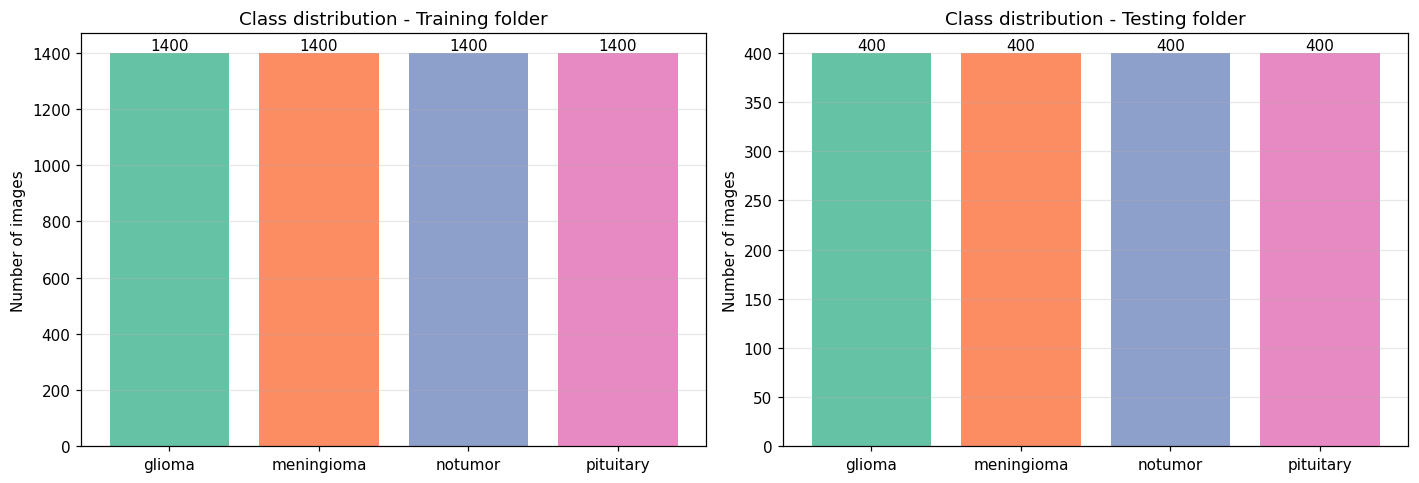

Share of each class in the whole dataset (%):
label
glioma        25.0
meningioma    25.0
notumor       25.0
pituitary     25.0


In [ ]:
# =============================================================
# CELL 6 - CLASS DISTRIBUTION
# =============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
palette = sns.color_palette("Set2", NUM_CLASSES)
for ax, split in zip(axes, ["Training", "Testing"]):
    vc = df_all[df_all.split == split].label.value_counts().reindex(CLASS_NAMES)
    bars = ax.bar(CLASS_NAMES, vc.values, color=palette)
    ax.bar_label(bars)
    ax.set_title(f"Class distribution - {split} folder")
    ax.set_ylabel("Number of images")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "class_distribution.png", bbox_inches="tight")
plt.show()

share = (df_all.label.value_counts(normalize=True).reindex(CLASS_NAMES) * 100).round(2)
print("Share of each class in the whole dataset (%):")
print(share.to_string())

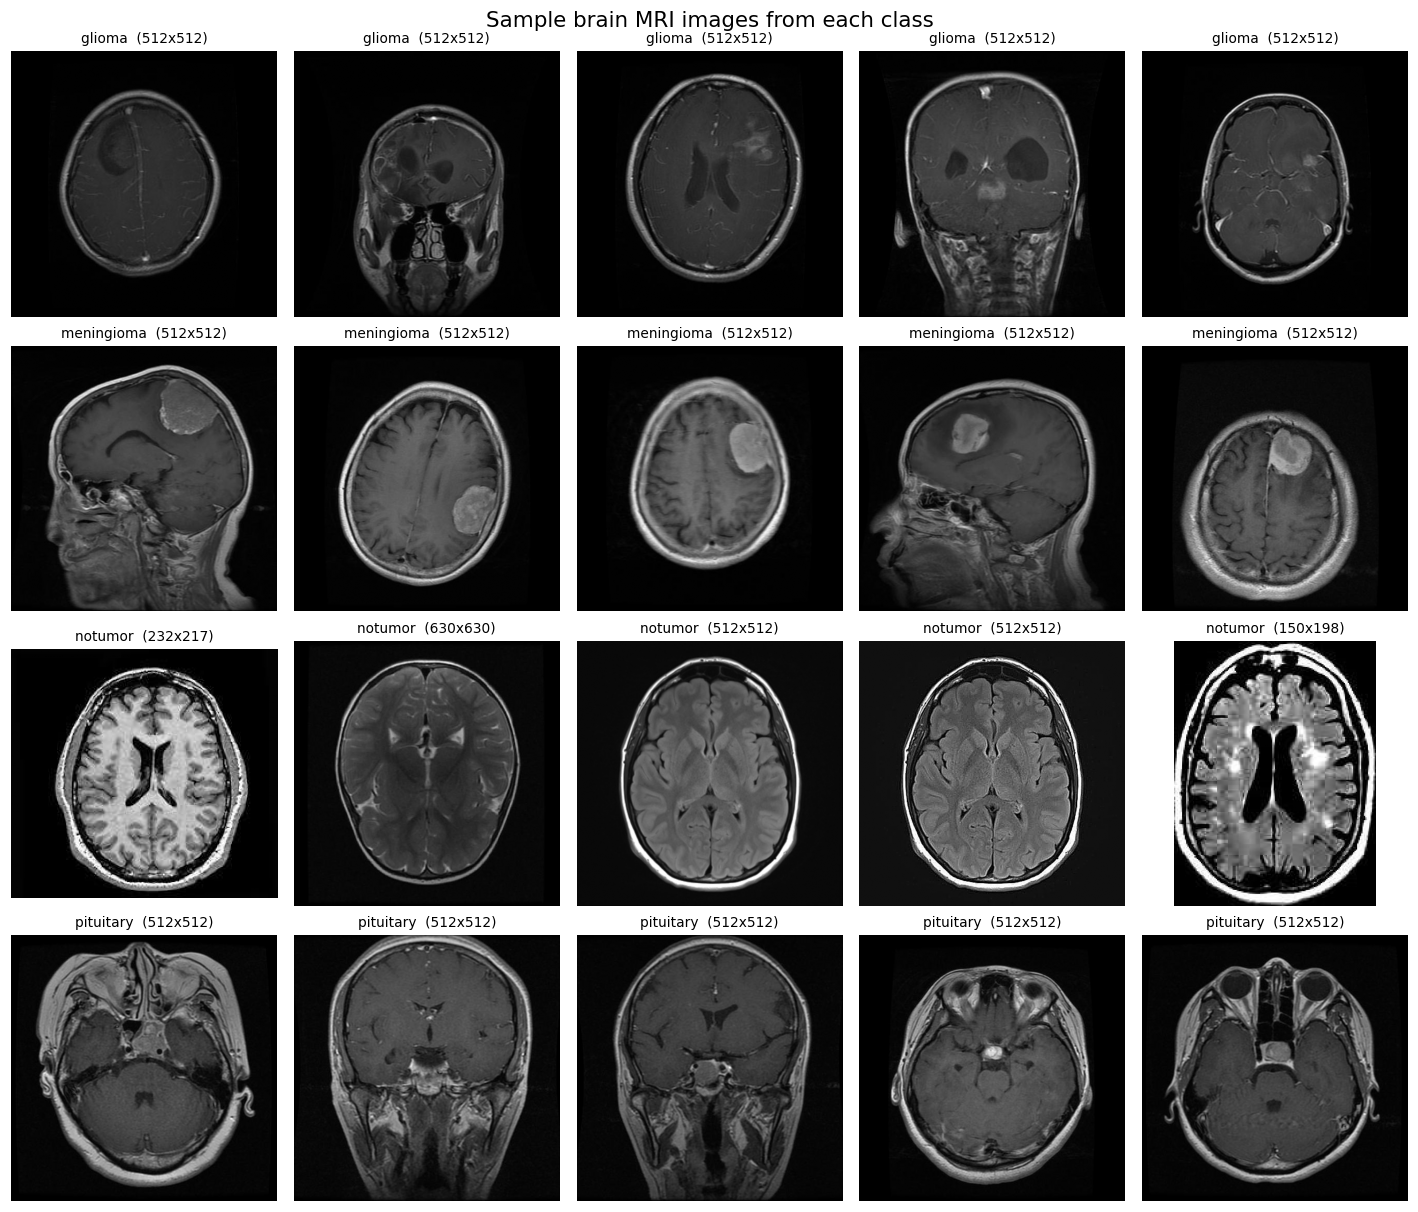

In [ ]:
# =============================================================
# CELL 7 - SAMPLE MRI IMAGES FROM EACH CLASS
# =============================================================
rng = np.random.default_rng(CONFIG["seed"])
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(13, 2.8 * NUM_CLASSES))
for r, c in enumerate(CLASS_NAMES):
    paths = df_all[(df_all.label == c) & (df_all.split == "Training")].path.values
    for k, p in enumerate(rng.choice(paths, 5, replace=False)):
        img = Image.open(p).convert("L")
        axes[r, k].imshow(img, cmap="gray")
        axes[r, k].set_title(f"{c}  ({img.size[0]}x{img.size[1]})", fontsize=9)
        axes[r, k].axis("off")
plt.suptitle("Sample brain MRI images from each class", fontsize=14)
plt.tight_layout()
plt.savefig(OUT / "sample_images.png", bbox_inches="tight")
plt.show()

Reading image headers:   0%|          | 0/7200 [00:00<?, ?it/s]

Colour modes found: {'L': 3067, 'RGB': 4129, 'RGBA': 3, 'P': 1}
Distinct resolutions: 447

Width / height statistics (pixels):


,width,height
count,7200.0,7200.0
mean,453.3,456.9
std,130.0,124.4
min,150.0,167.0
25%,442.0,449.0
50%,512.0,512.0
75%,512.0,512.0
max,1375.0,1446.0


Most common resolutions:


,width,height,count
0,512,512,5014
1,225,225,338
2,630,630,90
3,201,251,57
4,228,221,51


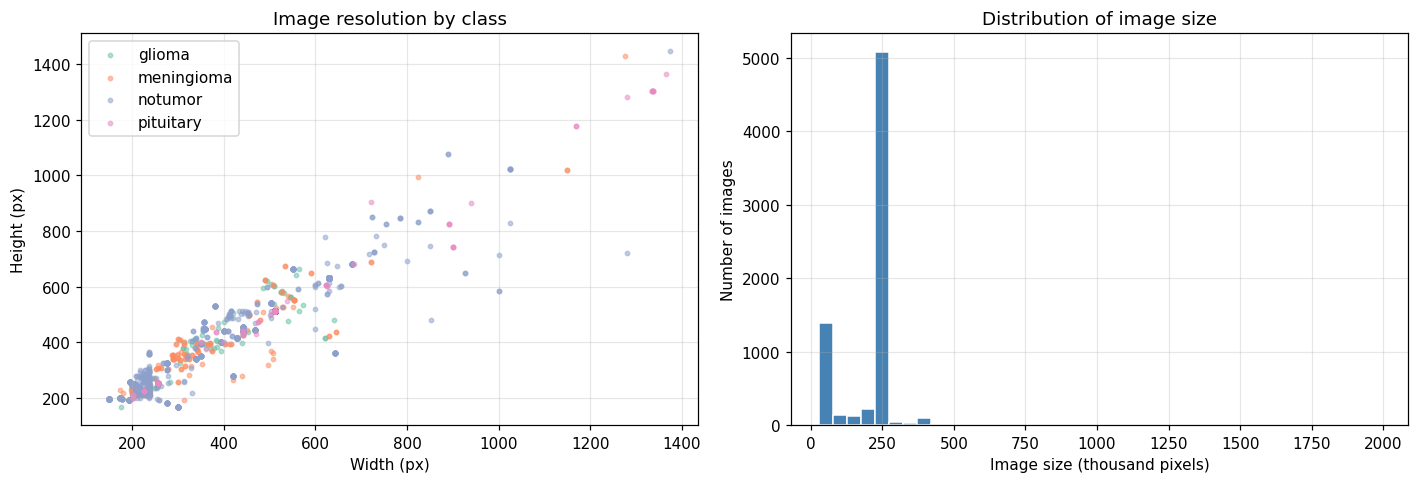

In [ ]:
# =============================================================
# CELL 8 - IMAGE RESOLUTION AND FORMAT ANALYSIS
# =============================================================
meta = []
for p in tqdm(df_all.path, desc="Reading image headers"):
    with Image.open(p) as im:
        meta.append((im.size[0], im.size[1], im.mode))
df_all["width"], df_all["height"], df_all["mode"] = zip(*meta)

print("Colour modes found:", dict(Counter(df_all["mode"])))
print("Distinct resolutions:", df_all.groupby(["width", "height"]).ngroups)
print("\nWidth / height statistics (pixels):")
display(df_all[["width", "height"]].describe().round(1))
print("Most common resolutions:")
display(df_all.groupby(["width", "height"]).size().sort_values(ascending=False).head(5).rename("count").reset_index())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for c, col in zip(CLASS_NAMES, palette):
    d = df_all[df_all.label == c]
    axes[0].scatter(d.width, d.height, s=8, alpha=0.5, label=c, color=col)
axes[0].set_xlabel("Width (px)"); axes[0].set_ylabel("Height (px)")
axes[0].set_title("Image resolution by class"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].hist(df_all.width * df_all.height / 1e3, bins=40, color="steelblue", edgecolor="white")
axes[1].set_xlabel("Image size (thousand pixels)"); axes[1].set_ylabel("Number of images")
axes[1].set_title("Distribution of image size"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "resolution_analysis.png", bbox_inches="tight")
plt.show()

In [ ]:
# =============================================================
# CELL 9 - DATA QUALITY AUDIT: DUPLICATE AND LEAKED IMAGES
# =============================================================
def file_md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df_all["md5"] = [file_md5(p) for p in tqdm(df_all.path, desc="Hashing files")]

train_hashes = set(df_all[df_all.split == "Training"].md5)
test_hashes = set(df_all[df_all.split == "Testing"].md5)
labels_per_hash = df_all.groupby("md5").label.nunique()
conflicting = set(labels_per_hash[labels_per_hash > 1].index)

print("Total image files                         :", len(df_all))
print("Unique images (by MD5 hash)               :", df_all.md5.nunique())
print("Extra copies of duplicate images          :", len(df_all) - df_all.md5.nunique())
print("Images present in BOTH Training and Testing:", len(train_hashes & test_hashes))
print("Duplicates with conflicting class labels  :", len(conflicting))

# Cleaning rule: the Testing folder is kept untouched as the final test set.
# From the Training folder we remove (1) any image that also appears in Testing (prevents leakage),
# (2) images whose copies carry different labels, and (3) repeated copies.
test_df = df_all[df_all.split == "Testing"].reset_index(drop=True)
train_pool = df_all[df_all.split == "Training"]
n_before = len(train_pool)
train_pool = train_pool[~train_pool.md5.isin(test_hashes)]
train_pool = train_pool[~train_pool.md5.isin(conflicting)]
train_pool = train_pool.drop_duplicates("md5").reset_index(drop=True)
print(f"\nTraining folder images: {n_before} -> {len(train_pool)} after cleaning "
      f"({n_before - len(train_pool)} removed)")
print("Testing images kept unchanged:", len(test_df))

Hashing files:   0%|          | 0/7200 [00:00<?, ?it/s]

Total image files                         : 7200
Unique images (by MD5 hash)               : 7013
Extra copies of duplicate images          : 187
Images present in BOTH Training and Testing: 0
Duplicates with conflicting class labels  : 0

Training folder images: 5600 -> 5429 after cleaning (171 removed)
Testing images kept unchanged: 1600


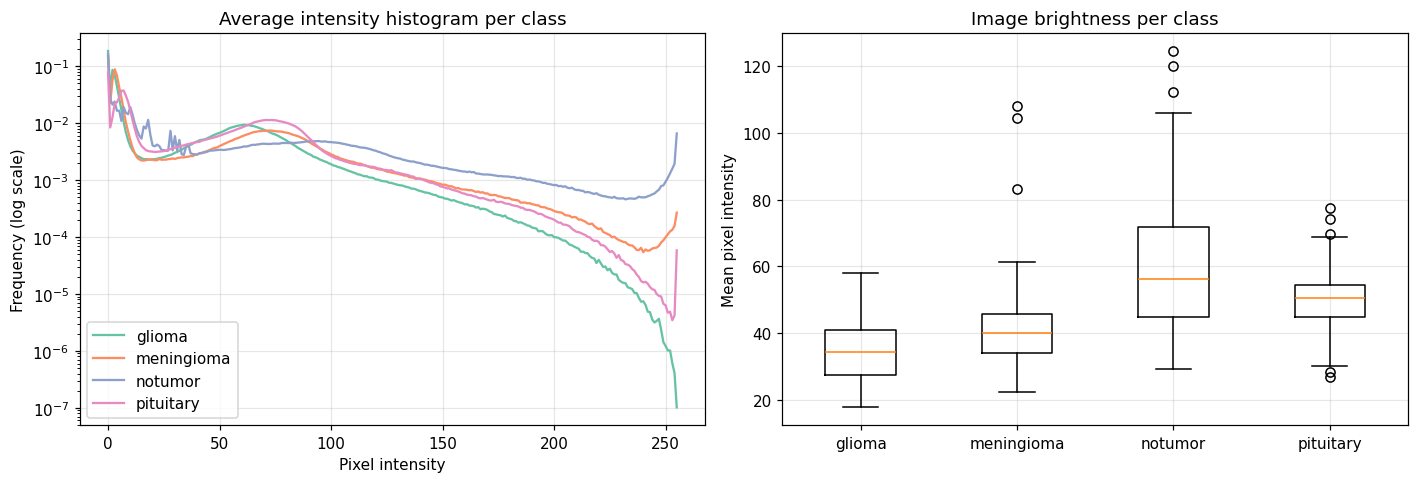

,class,images sampled,mean brightness,mean contrast (std),dark pixels (<10) %
0,glioma,150,35.03,38.77,49.07
1,meningioma,150,41.33,46.12,49.20
2,notumor,150,60.48,58.77,32.67
3,pituitary,150,49.76,41.80,30.29


In [ ]:
# =============================================================
# CELL 10 - PIXEL INTENSITY ANALYSIS PER CLASS
# =============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rows, means_per_class = [], []
for c, col in zip(CLASS_NAMES, palette):
    paths = train_pool[train_pool.label == c].path.sample(min(150, (train_pool.label == c).sum()),
                                                           random_state=CONFIG["seed"])
    hist, means, stds = np.zeros(256), [], []
    for p in paths:
        a = np.array(Image.open(p).convert("L").resize((256, 256)))
        hist += np.bincount(a.ravel(), minlength=256)
        means.append(a.mean()); stds.append(a.std())
    axes[0].plot(hist / hist.sum(), label=c, color=col)
    means_per_class.append(means)
    rows.append({"class": c, "images sampled": len(means), "mean brightness": round(np.mean(means), 2),
                 "mean contrast (std)": round(np.mean(stds), 2), "dark pixels (<10) %": round(hist[:10].sum() / hist.sum() * 100, 2)})
axes[0].set_yscale("log"); axes[0].set_xlabel("Pixel intensity"); axes[0].set_ylabel("Frequency (log scale)")
axes[0].set_title("Average intensity histogram per class"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].boxplot(means_per_class)
axes[1].set_xticks(range(1, NUM_CLASSES + 1))
axes[1].set_xticklabels(CLASS_NAMES)
axes[1].set_ylabel("Mean pixel intensity"); axes[1].set_title("Image brightness per class"); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "intensity_analysis.png", bbox_inches="tight")
plt.show()
display(pd.DataFrame(rows))

## C. Preprocessing and Data Pipeline

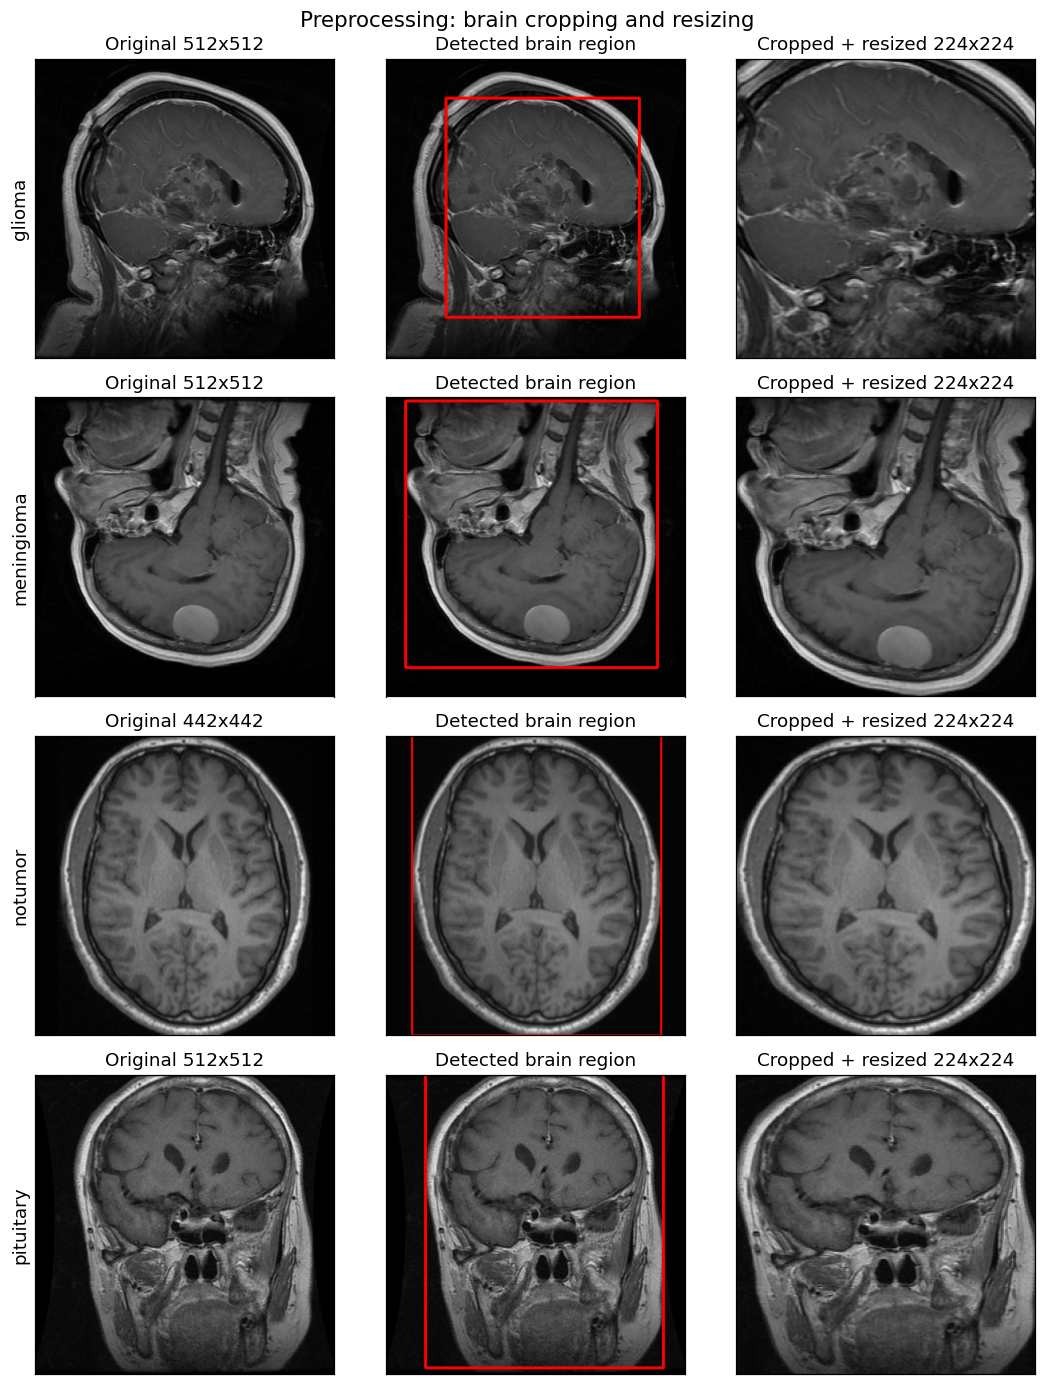

In [ ]:
# =============================================================
# CELL 11 - BRAIN REGION CROPPING (REMOVE BLACK BACKGROUND)
# =============================================================
def crop_brain(gray):
    """Crop the image to the largest bright region (the head) using Otsu thresholding."""
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, mask = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8), iterations=2)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return gray, None
    x, y, w, h = cv2.boundingRect(max(contours, key=cv2.contourArea))
    if w * h < 0.10 * gray.shape[0] * gray.shape[1]:      # too small: keep the full image
        return gray, None
    return gray[y:y + h, x:x + w], (x, y, w, h)

def read_gray(path):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if g is None:                                          # fallback for unusual files
        g = np.array(Image.open(path).convert("L"))
    return g

def load_preprocessed(path, size=CONFIG["cache_size"]):
    cropped, _ = crop_brain(read_gray(path))
    return cv2.resize(cropped, (size, size), interpolation=cv2.INTER_AREA)

demo_paths = [train_pool[train_pool.label == c].path.iloc[3] for c in CLASS_NAMES]
fig, axes = plt.subplots(len(demo_paths), 3, figsize=(10, 3.2 * len(demo_paths)))
for r, p in enumerate(demo_paths):
    g = read_gray(p)
    cropped, box = crop_brain(g)
    boxed = cv2.cvtColor(g, cv2.COLOR_GRAY2RGB)
    if box:
        x, y, w, h = box
        cv2.rectangle(boxed, (x, y), (x + w, y + h), (255, 0, 0), max(2, g.shape[0] // 150))
    axes[r, 0].imshow(g, cmap="gray"); axes[r, 0].set_title(f"Original {g.shape[1]}x{g.shape[0]}")
    axes[r, 1].imshow(boxed); axes[r, 1].set_title("Detected brain region")
    axes[r, 2].imshow(cv2.resize(cropped, (CONFIG["img_size"],) * 2), cmap="gray")
    axes[r, 2].set_title(f"Cropped + resized {CONFIG['img_size']}x{CONFIG['img_size']}")
    axes[r, 0].set_ylabel(df_all.set_index("path").loc[p, "label"], fontsize=12)
    for a in axes[r]: a.set_xticks([]); a.set_yticks([])
plt.suptitle("Preprocessing: brain cropping and resizing", fontsize=14)
plt.tight_layout()
plt.savefig(OUT / "preprocessing_steps.png", bbox_inches="tight")
plt.show()

In [ ]:
# =============================================================
# CELL 12 - TRAIN / VALIDATION / TEST SPLIT AND IMAGE CACHE
# =============================================================
def build_cache(df, desc):
    size = CONFIG["cache_size"]
    arr = np.zeros((len(df), size, size), dtype=np.uint8)
    for i, p in enumerate(tqdm(df.path.values, desc=desc)):
        arr[i] = load_preprocessed(p)
    return arr

tr_idx, va_idx = train_test_split(np.arange(len(train_pool)), test_size=CONFIG["val_fraction"],
                                  stratify=train_pool.y, random_state=CONFIG["seed"])
X_pool = build_cache(train_pool, "Preprocessing Training folder")
X_test = build_cache(test_df, "Preprocessing Testing folder")
X_tr, y_tr = X_pool[tr_idx], train_pool.y.values[tr_idx]
X_va, y_va = X_pool[va_idx], train_pool.y.values[va_idx]
y_test = test_df.y.values
del X_pool

split_table = pd.DataFrame({
    "Train": pd.Series(y_tr).map(dict(enumerate(CLASS_NAMES))).value_counts(),
    "Validation": pd.Series(y_va).map(dict(enumerate(CLASS_NAMES))).value_counts(),
    "Test": test_df.label.value_counts(),
}).reindex(CLASS_NAMES)
split_table.loc["TOTAL"] = split_table.sum()
display(split_table)
print(f"Memory used by cached images: {(X_tr.nbytes + X_va.nbytes + X_test.nbytes) / 1e6:.1f} MB")

Preprocessing Training folder:   0%|          | 0/5429 [00:00<?, ?it/s]

Preprocessing Testing folder:   0%|          | 0/1600 [00:00<?, ?it/s]

,Train,Validation,Test
glioma,1190,210,400
meningioma,1178,208,400
notumor,1089,192,400
pituitary,1157,205,400
TOTAL,4614,815,1600


Memory used by cached images: 460.7 MB


Batches -> train: 145, validation: 13, test: 25
Batch tensor shape: (32, 3, 224, 224)


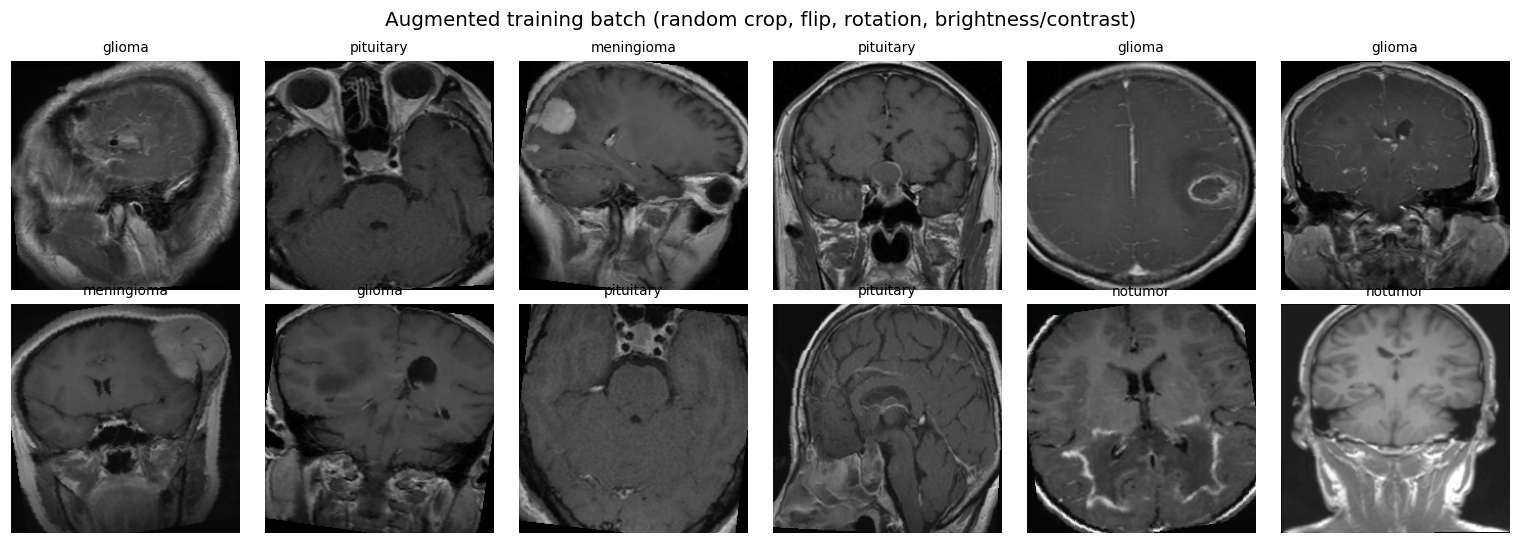

In [ ]:
# =============================================================
# CELL 13 - PYTORCH DATASET, AUGMENTATION AND DATA LOADERS
# =============================================================
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet statistics
S = CONFIG["img_size"]

train_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomResizedCrop(S, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((S, S)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class MRIDataset(Dataset):
    def __init__(self, images, labels, tf):
        self.images, self.labels, self.tf = images, labels, tf
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        return self.tf(self.images[i]), int(self.labels[i])

nw = 2 if DEVICE.type == "cuda" else 0
pin = DEVICE.type == "cuda"
train_loader = DataLoader(MRIDataset(X_tr, y_tr, train_tf), batch_size=CONFIG["batch_size"], shuffle=True, num_workers=nw, pin_memory=pin)
val_loader = DataLoader(MRIDataset(X_va, y_va, eval_tf), batch_size=64, shuffle=False, num_workers=nw, pin_memory=pin)
test_loader = DataLoader(MRIDataset(X_test, y_test, eval_tf), batch_size=64, shuffle=False, num_workers=nw, pin_memory=pin)
print(f"Batches -> train: {len(train_loader)}, validation: {len(val_loader)}, test: {len(test_loader)}")

def denorm(t):
    return (t.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)).clip(0, 1)

xb, yb = next(iter(train_loader))
print("Batch tensor shape:", tuple(xb.shape))
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for a, img, lab in zip(axes.ravel(), xb[:12], yb[:12]):
    a.imshow(denorm(img)); a.set_title(CLASS_NAMES[lab], fontsize=9); a.axis("off")
plt.suptitle("Augmented training batch (random crop, flip, rotation, brightness/contrast)", fontsize=13)
plt.tight_layout()
plt.savefig(OUT / "augmented_batch.png", bbox_inches="tight")
plt.show()

## D. Model Training

In [ ]:
# =============================================================
# CELL 14 - TRAINING AND VALIDATION FUNCTIONS
# =============================================================
USE_AMP = DEVICE.type == "cuda"

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def fit(model, name, epochs, lr):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CONFIG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
    history, best_acc, best_state, bad_epochs = [], -1.0, None, 0
    start = time.time()
    print(f"Training {name} for up to {epochs} epochs (lr={lr})")
    for ep in range(1, epochs + 1):
        t = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        lr_now = optimizer.param_groups[0]["lr"]
        scheduler.step()
        improved = va_acc > best_acc
        if improved:
            best_acc, bad_epochs = va_acc, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
        history.append({"epoch": ep, "train_loss": tr_loss, "train_acc": tr_acc,
                        "val_loss": va_loss, "val_acc": va_acc, "lr": lr_now, "time_s": time.time() - t})
        print(f"[{name}] Epoch {ep:02d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | {time.time() - t:5.1f}s" + ("  * best" if improved else ""))
        if bad_epochs >= CONFIG["patience"]:
            print(f"Early stopping: no improvement for {CONFIG['patience']} epochs.")
            break
    model.load_state_dict(best_state)
    torch.save(best_state, OUT / f"{name}.pt")
    total = time.time() - start
    print(f"Finished {name}: best validation accuracy {best_acc:.4f}, training time {total / 60:.1f} min")
    hist = pd.DataFrame(history)
    hist.attrs.update({"best_val_acc": best_acc, "train_minutes": total / 60})
    return model, hist

def count_params(model):
    return sum(p.numel() for p in model.parameters())

MODELS, HISTORIES = {}, {}
print("Training utilities ready. Mixed precision:", USE_AMP)

Training utilities ready. Mixed precision: True


In [ ]:
# =============================================================
# CELL 15 - MODEL 1: BASELINE CNN (TRAINED FROM SCRATCH)
# =============================================================
class BaselineCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

set_seed(CONFIG["seed"])
cnn = BaselineCNN(NUM_CLASSES)
print(cnn)
print(f"\nTrainable parameters: {count_params(cnn):,}")

BaselineCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(in

In [ ]:
# =============================================================
# CELL 16 - TRAIN THE BASELINE CNN
# =============================================================
MODELS["Baseline CNN"], HISTORIES["Baseline CNN"] = fit(cnn, "baseline_cnn", CONFIG["epochs_cnn"], CONFIG["lr_cnn"])

Training baseline_cnn for up to 15 epochs (lr=0.001)
[baseline_cnn] Epoch 01/15 | train loss 0.9516 acc 0.6038 | val loss 0.9821 acc 0.5215 |  23.6s  * best
[baseline_cnn] Epoch 02/15 | train loss 0.7988 acc 0.6849 | val loss 1.0715 acc 0.5926 |  20.1s  * best
[baseline_cnn] Epoch 03/15 | train loss 0.6494 acc 0.7523 | val loss 0.7143 acc 0.6798 |  18.1s  * best
[baseline_cnn] Epoch 04/15 | train loss 0.5799 acc 0.7839 | val loss 1.6622 acc 0.5276 |  18.2s
[baseline_cnn] Epoch 05/15 | train loss 0.5227 acc 0.8054 | val loss 0.7915 acc 0.7276 |  20.1s  * best
[baseline_cnn] Epoch 06/15 | train loss 0.4827 acc 0.8260 | val loss 0.6600 acc 0.7215 |  18.7s
[baseline_cnn] Epoch 07/15 | train loss 0.4473 acc 0.8366 | val loss 0.7980 acc 0.7215 |  22.1s
[baseline_cnn] Epoch 08/15 | train loss 0.4010 acc 0.8546 | val loss 0.4184 acc 0.8589 |  18.3s  * best
[baseline_cnn] Epoch 09/15 | train loss 0.3716 acc 0.8687 | val loss 0.3436 acc 0.8847 |  19.7s  * best
[baseline_cnn] Epoch 10/15 | train 

In [ ]:
# =============================================================
# CELL 17 - MODEL 2: RESNET-18 (TRANSFER LEARNING FROM IMAGENET)
# =============================================================
set_seed(CONFIG["seed"])
resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if CONFIG["pretrained"] else None)
resnet.fc = nn.Linear(resnet.fc.in_features, NUM_CLASSES)
print("Classifier head:", resnet.fc)
print(f"Trainable parameters: {count_params(resnet):,}")
MODELS["ResNet-18"], HISTORIES["ResNet-18"] = fit(resnet, "resnet18", CONFIG["epochs_resnet"], CONFIG["lr_pretrained"])

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


Classifier head: Linear(in_features=512, out_features=4, bias=True)
Trainable parameters: 11,178,564
Training resnet18 for up to 10 epochs (lr=0.0003)
[resnet18] Epoch 01/10 | train loss 0.3292 acc 0.8726 | val loss 0.3075 acc 0.8920 |  18.2s  * best
[resnet18] Epoch 02/10 | train loss 0.1472 acc 0.9473 | val loss 0.1149 acc 0.9534 |  17.0s  * best
[resnet18] Epoch 03/10 | train loss 0.1254 acc 0.9560 | val loss 0.1007 acc 0.9742 |  16.9s  * best
[resnet18] Epoch 04/10 | train loss 0.0708 acc 0.9770 | val loss 0.1058 acc 0.9718 |  18.2s
[resnet18] Epoch 05/10 | train loss 0.0490 acc 0.9835 | val loss 0.0579 acc 0.9865 |  16.9s  * best
[resnet18] Epoch 06/10 | train loss 0.0330 acc 0.9885 | val loss 0.0513 acc 0.9840 |  17.0s
[resnet18] Epoch 07/10 | train loss 0.0200 acc 0.9937 | val loss 0.0595 acc 0.9840 |  17.0s
[resnet18] Epoch 08/10 | train loss 0.0177 acc 0.9939 | val loss 0.0488 acc 0.9890 |  17.4s  * best
[resnet18] Epoch 09/10 | train loss 0.0141 acc 0.9957 | val loss 0.0476 a

In [ ]:
# =============================================================
# CELL 18 - MODEL 3: EFFICIENTNET-B0 (TRANSFER LEARNING FROM IMAGENET)
# =============================================================
set_seed(CONFIG["seed"])
effnet = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if CONFIG["pretrained"] else None)
effnet.classifier[1] = nn.Linear(effnet.classifier[1].in_features, NUM_CLASSES)
print("Classifier head:", effnet.classifier)
print(f"Trainable parameters: {count_params(effnet):,}")
MODELS["EfficientNet-B0"], HISTORIES["EfficientNet-B0"] = fit(effnet, "efficientnet_b0", CONFIG["epochs_effnet"], CONFIG["lr_pretrained"])

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 147MB/s]


Classifier head: Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)
Trainable parameters: 4,012,672
Training efficientnet_b0 for up to 10 epochs (lr=0.0003)
[efficientnet_b0] Epoch 01/10 | train loss 0.3673 acc 0.8658 | val loss 0.0933 acc 0.9669 |  29.4s  * best
[efficientnet_b0] Epoch 02/10 | train loss 0.1282 acc 0.9523 | val loss 0.0539 acc 0.9791 |  21.4s  * best
[efficientnet_b0] Epoch 03/10 | train loss 0.0806 acc 0.9723 | val loss 0.0545 acc 0.9804 |  22.7s  * best
[efficientnet_b0] Epoch 04/10 | train loss 0.0714 acc 0.9762 | val loss 0.0375 acc 0.9853 |  23.0s  * best
[efficientnet_b0] Epoch 05/10 | train loss 0.0426 acc 0.9866 | val loss 0.0350 acc 0.9865 |  21.3s  * best
[efficientnet_b0] Epoch 06/10 | train loss 0.0249 acc 0.9926 | val loss 0.0560 acc 0.9828 |  22.8s
[efficientnet_b0] Epoch 07/10 | train loss 0.0196 acc 0.9931 | val loss 0.0470 acc 0.9840 |  22.4s
[efficientnet_b0] Epoch 08/10 | train loss 0.0133 ac

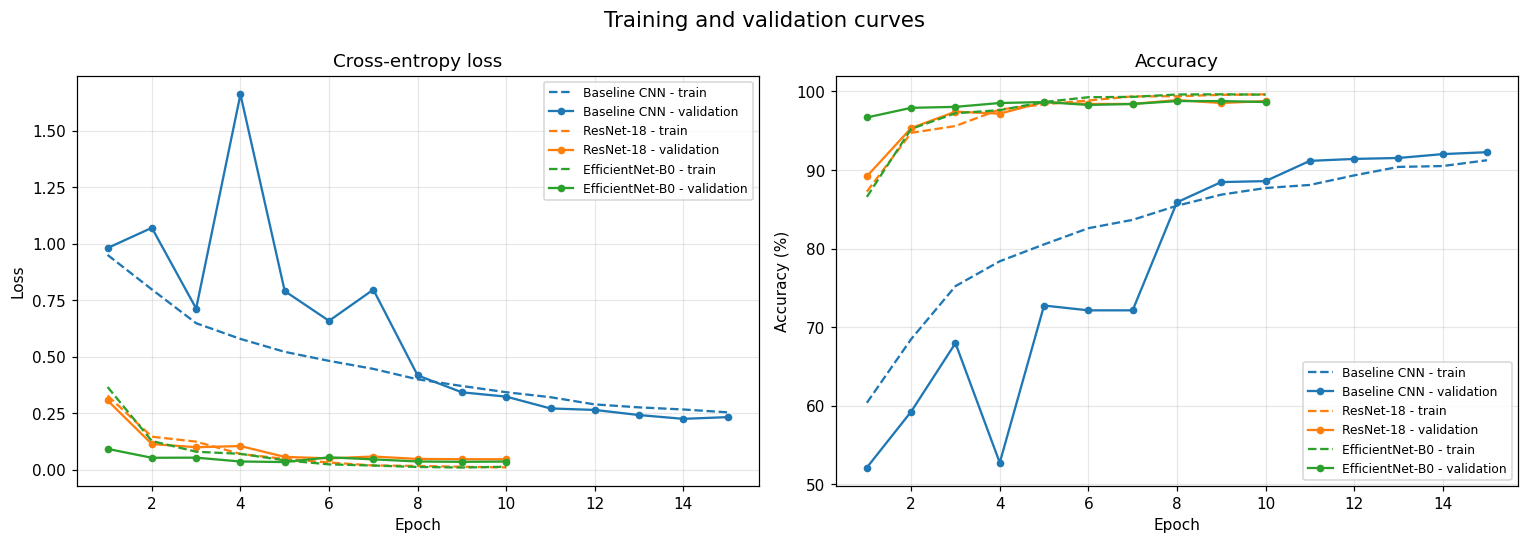

,Model,Epochs run,Best val accuracy,Training time (min)
0,Baseline CNN,15,0.9227,4.90
1,ResNet-18,10,0.9890,2.87
2,EfficientNet-B0,10,0.9877,3.82


In [ ]:
# =============================================================
# CELL 19 - LEARNING CURVES OF ALL MODELS
# =============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for (name, h), col in zip(HISTORIES.items(), sns.color_palette("tab10", 3)):
    axes[0].plot(h.epoch, h.train_loss, "--", color=col, label=f"{name} - train")
    axes[0].plot(h.epoch, h.val_loss, "-o", color=col, ms=4, label=f"{name} - validation")
    axes[1].plot(h.epoch, h.train_acc * 100, "--", color=col, label=f"{name} - train")
    axes[1].plot(h.epoch, h.val_acc * 100, "-o", color=col, ms=4, label=f"{name} - validation")
axes[0].set_title("Cross-entropy loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)")
for a in axes: a.grid(alpha=0.3); a.legend(fontsize=8)
plt.suptitle("Training and validation curves", fontsize=14)
plt.tight_layout()
plt.savefig(OUT / "learning_curves.png", bbox_inches="tight")
plt.show()

display(pd.DataFrame([{"Model": n, "Epochs run": len(h), "Best val accuracy": round(h.attrs["best_val_acc"], 4),
                       "Training time (min)": round(h.attrs["train_minutes"], 2)} for n, h in HISTORIES.items()]))

## E. Evaluation on the Held-out Test Set

In [ ]:
# =============================================================
# CELL 20 - TEST SET EVALUATION AND MODEL COMPARISON
# =============================================================
@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    probs = []
    for x, _ in loader:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(x.to(DEVICE))
        probs.append(F.softmax(out.float(), dim=1).cpu().numpy())
    return np.concatenate(probs)

@torch.no_grad()
def latency_ms(model, runs=50):
    model.eval()
    x = torch.randn(1, 3, S, S, device=DEVICE)
    for _ in range(10): model(x)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t = time.time()
    for _ in range(runs): model(x)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t) / runs * 1000

PROBS, rows = {}, []
for name, m in MODELS.items():
    prob = predict_loader(m, test_loader)
    PROBS[name] = prob
    pred = prob.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    rows.append({"Model": name,
                 "Test accuracy": accuracy_score(y_test, pred),
                 "Macro precision": p, "Macro recall": r, "Macro F1": f1,
                 "Macro ROC-AUC": roc_auc_score(y_test, prob, multi_class="ovr"),
                 "Parameters (M)": count_params(m) / 1e6,
                 "Inference (ms/image)": latency_ms(m)})
results_df = pd.DataFrame(rows).round(4)
results_df.to_csv(OUT / "model_comparison.csv", index=False)
display(results_df)

,Model,Test accuracy,Macro precision,Macro recall,Macro F1,Macro ROC-AUC,Parameters (M),Inference (ms/image)
0,Baseline CNN,0.8738,0.8802,0.8738,0.8711,0.9642,1.1742,3.2545
1,ResNet-18,0.9512,0.9545,0.9512,0.9504,0.9903,11.1786,3.5731
2,EfficientNet-B0,0.9600,0.9626,0.9600,0.9594,0.9932,4.0127,10.8624


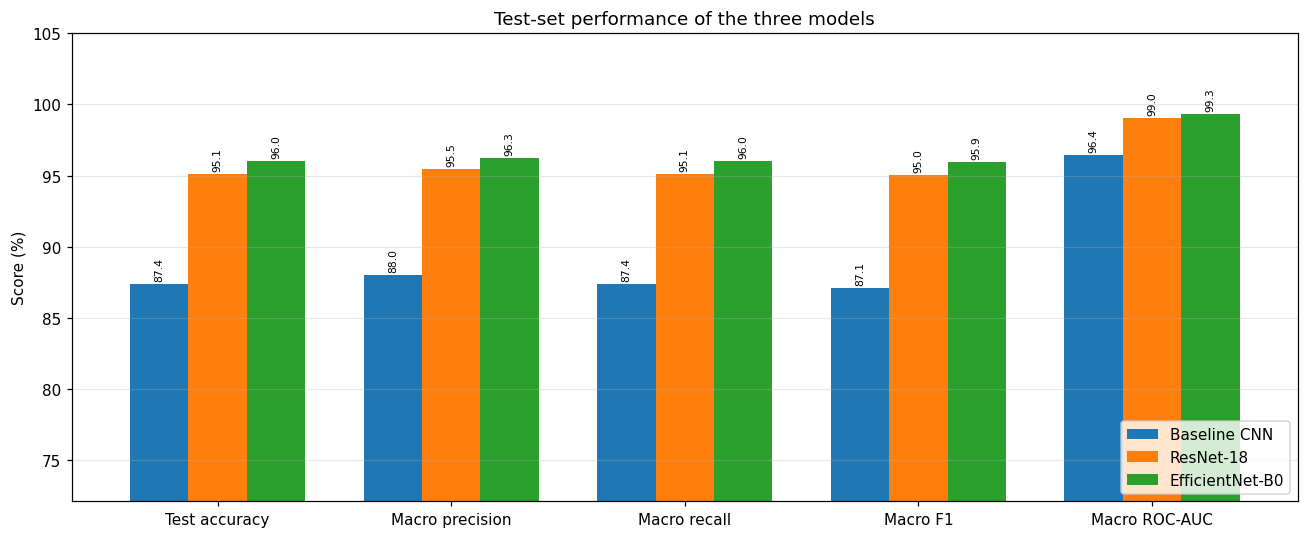

In [ ]:
# =============================================================
# CELL 21 - MODEL COMPARISON CHART
# =============================================================
metrics = ["Test accuracy", "Macro precision", "Macro recall", "Macro F1", "Macro ROC-AUC"]
plot_df = results_df.set_index("Model")[metrics] * 100
ax = plot_df.T.plot(kind="bar", figsize=(12, 5), width=0.75, color=sns.color_palette("tab10", 3))
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f", fontsize=7, rotation=90, padding=2)
ax.set_ylabel("Score (%)"); ax.set_ylim(max(0, plot_df.values.min() - 15), 105)
ax.set_title("Test-set performance of the three models"); ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0); plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUT / "model_comparison.png", bbox_inches="tight")
plt.show()

In [ ]:
# =============================================================
# CELL 22 - BEST MODEL (CHOSEN BY VALIDATION ACCURACY): CLASSIFICATION REPORT
# =============================================================
BEST_NAME = max(HISTORIES, key=lambda n: HISTORIES[n].attrs["best_val_acc"])
best_model = MODELS[BEST_NAME]
best_prob = PROBS[BEST_NAME]
best_pred = best_prob.argmax(1)
print("Best model (highest validation accuracy):", BEST_NAME)
print(f"Test accuracy: {accuracy_score(y_test, best_pred):.4f}\n")
print(classification_report(y_test, best_pred, target_names=CLASS_NAMES, digits=4))
report_df = pd.DataFrame(classification_report(y_test, best_pred, target_names=CLASS_NAMES, output_dict=True)).T.round(4)
report_df.to_csv(OUT / "best_model_classification_report.csv")

Best model (highest validation accuracy): ResNet-18
Test accuracy: 0.9513

              precision    recall  f1-score   support

      glioma     0.9911    0.8350    0.9064       400
  meningioma     0.8957    0.9875    0.9394       400
     notumor     0.9390    1.0000    0.9685       400
   pituitary     0.9924    0.9825    0.9874       400

    accuracy                         0.9513      1600
   macro avg     0.9545    0.9512    0.9504      1600
weighted avg     0.9545    0.9513    0.9504      1600



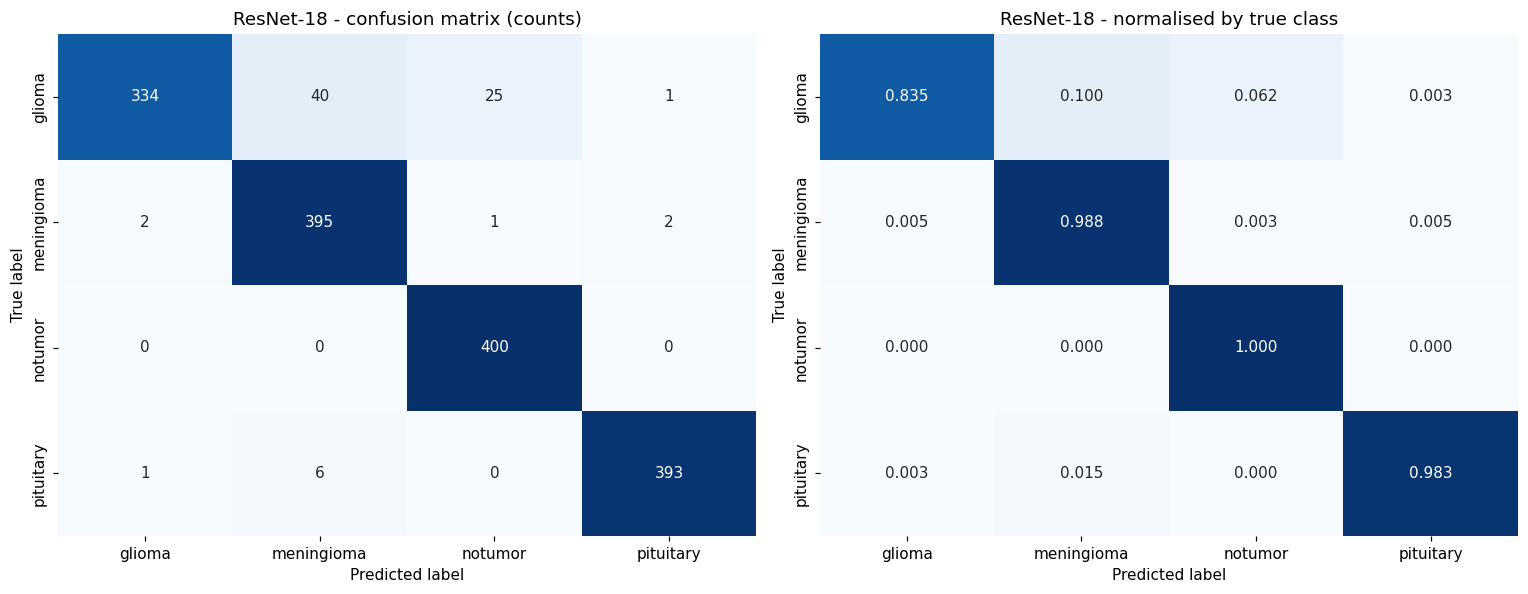

Correct: 1522 | Wrong: 78 | Total: 1600


In [ ]:
# =============================================================
# CELL 23 - CONFUSION MATRIX OF THE BEST MODEL
# =============================================================
cm = confusion_matrix(y_test, best_pred)
cm_norm = confusion_matrix(y_test, best_pred, normalize="true")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0], cbar=False)
sns.heatmap(cm_norm, annot=True, fmt=".3f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1], cbar=False)
axes[0].set_title(f"{BEST_NAME} - confusion matrix (counts)")
axes[1].set_title(f"{BEST_NAME} - normalised by true class")
for a in axes: a.set_xlabel("Predicted label"); a.set_ylabel("True label")
plt.tight_layout()
plt.savefig(OUT / "confusion_matrix.png", bbox_inches="tight")
plt.show()
print("Correct:", int(np.trace(cm)), "| Wrong:", int(cm.sum() - np.trace(cm)), "| Total:", int(cm.sum()))

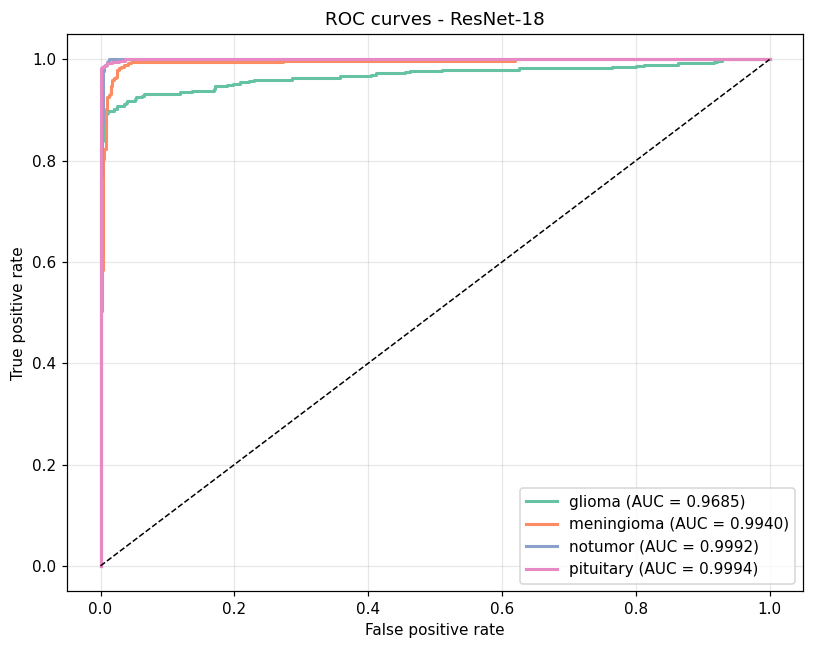

In [ ]:
# =============================================================
# CELL 24 - ROC CURVES (ONE-VS-REST) FOR THE BEST MODEL
# =============================================================
y_bin = label_binarize(y_test, classes=list(range(NUM_CLASSES)))
plt.figure(figsize=(7.5, 6))
for i, (c, col) in enumerate(zip(CLASS_NAMES, palette)):
    fpr, tpr, _ = roc_curve(y_bin[:, i], best_prob[:, i])
    plt.plot(fpr, tpr, color=col, lw=2, label=f"{c} (AUC = {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title(f"ROC curves - {BEST_NAME}"); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "roc_curves.png", bbox_inches="tight")
plt.show()

Misclassified test images: 78 of 1600


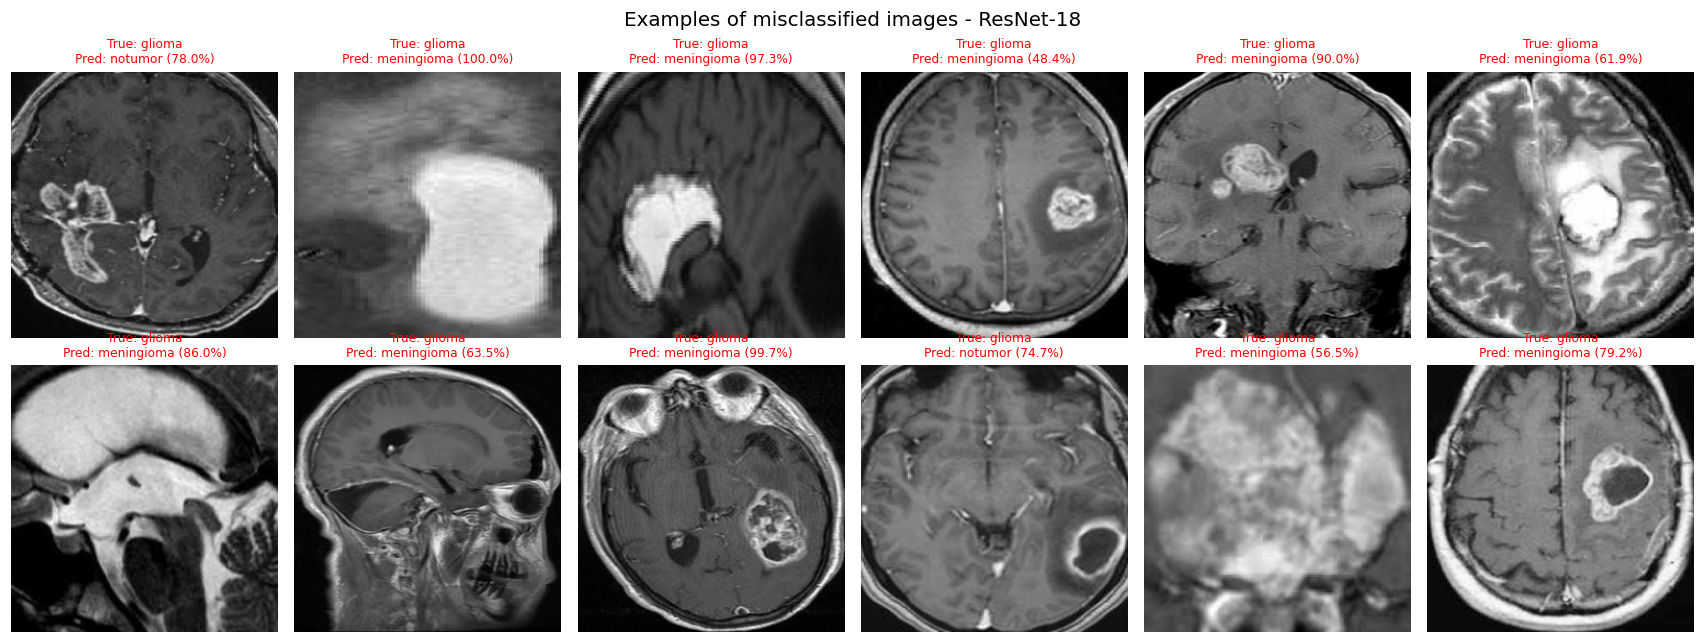

,True class,Predicted as,Count
0,glioma,meningioma,40
1,glioma,notumor,25
2,pituitary,meningioma,6
3,meningioma,glioma,2
4,meningioma,pituitary,2
5,glioma,pituitary,1
6,meningioma,notumor,1
7,pituitary,glioma,1


In [ ]:
# =============================================================
# CELL 25 - MISCLASSIFIED TEST IMAGES
# =============================================================
wrong = np.where(best_pred != y_test)[0]
print(f"Misclassified test images: {len(wrong)} of {len(y_test)}")
if len(wrong):
    show = wrong[:12]
    cols = min(6, len(show)); rows_n = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(2.6 * cols, 3 * rows_n), squeeze=False)
    for a in axes.ravel(): a.axis("off")
    for a, i in zip(axes.ravel(), show):
        a.imshow(X_test[i], cmap="gray")
        a.set_title(f"True: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[best_pred[i]]} ({best_prob[i].max() * 100:.1f}%)", fontsize=8, color="red")
    plt.suptitle(f"Examples of misclassified images - {BEST_NAME}", fontsize=13)
    plt.tight_layout()
    plt.savefig(OUT / "misclassified.png", bbox_inches="tight")
    plt.show()
    pairs = Counter((CLASS_NAMES[y_test[i]], CLASS_NAMES[best_pred[i]]) for i in wrong)
    display(pd.DataFrame([{"True class": t, "Predicted as": p, "Count": n} for (t, p), n in pairs.most_common()]))

## F. Explainability with Grad-CAM

In [ ]:
# =============================================================
# CELL 26 - GRAD-CAM IMPLEMENTATION
# =============================================================
class GradCAM:
    """Gradient-weighted Class Activation Mapping (Selvaraju et al., 2017)."""
    def __init__(self, model, target_layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = target_layer.register_forward_hook(self._forward_hook)
    def _forward_hook(self, module, inp, out):
        self.acts = out
        out.register_hook(self._save_grad)
    def _save_grad(self, grad):
        self.grads = grad
    def __call__(self, x, class_idx=None):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = self.model(x)
            probs = F.softmax(logits, dim=1)
            if class_idx is None:
                class_idx = int(logits.argmax(1))
            logits[0, class_idx].backward()
        weights = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.acts).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), class_idx, float(probs[0, class_idx])
    def remove(self):
        self.handle.remove()

TARGET_LAYERS = {
    "Baseline CNN": lambda m: m.features[-1],
    "ResNet-18": lambda m: m.layer4[-1],
    "EfficientNet-B0": lambda m: m.features[-1],
}

def overlay(gray, cam, alpha=0.4):
    heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    base = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    return np.uint8(alpha * heat + (1 - alpha) * base)

def gradcam_for(model_name, idx):
    m = MODELS[model_name].float()
    cam_obj = GradCAM(m, TARGET_LAYERS[model_name](m))
    x = eval_tf(X_test[idx]).unsqueeze(0).to(DEVICE)
    cam, cls, conf = cam_obj(x)
    cam_obj.remove()
    gray = cv2.resize(X_test[idx], (S, S))
    return gray, cam, cls, conf

print("Grad-CAM ready. Target layers:", {k: type(v(MODELS[k])).__name__ for k, v in TARGET_LAYERS.items()})

Grad-CAM ready. Target layers: {'Baseline CNN': 'Sequential', 'ResNet-18': 'BasicBlock', 'EfficientNet-B0': 'Conv2dNormActivation'}


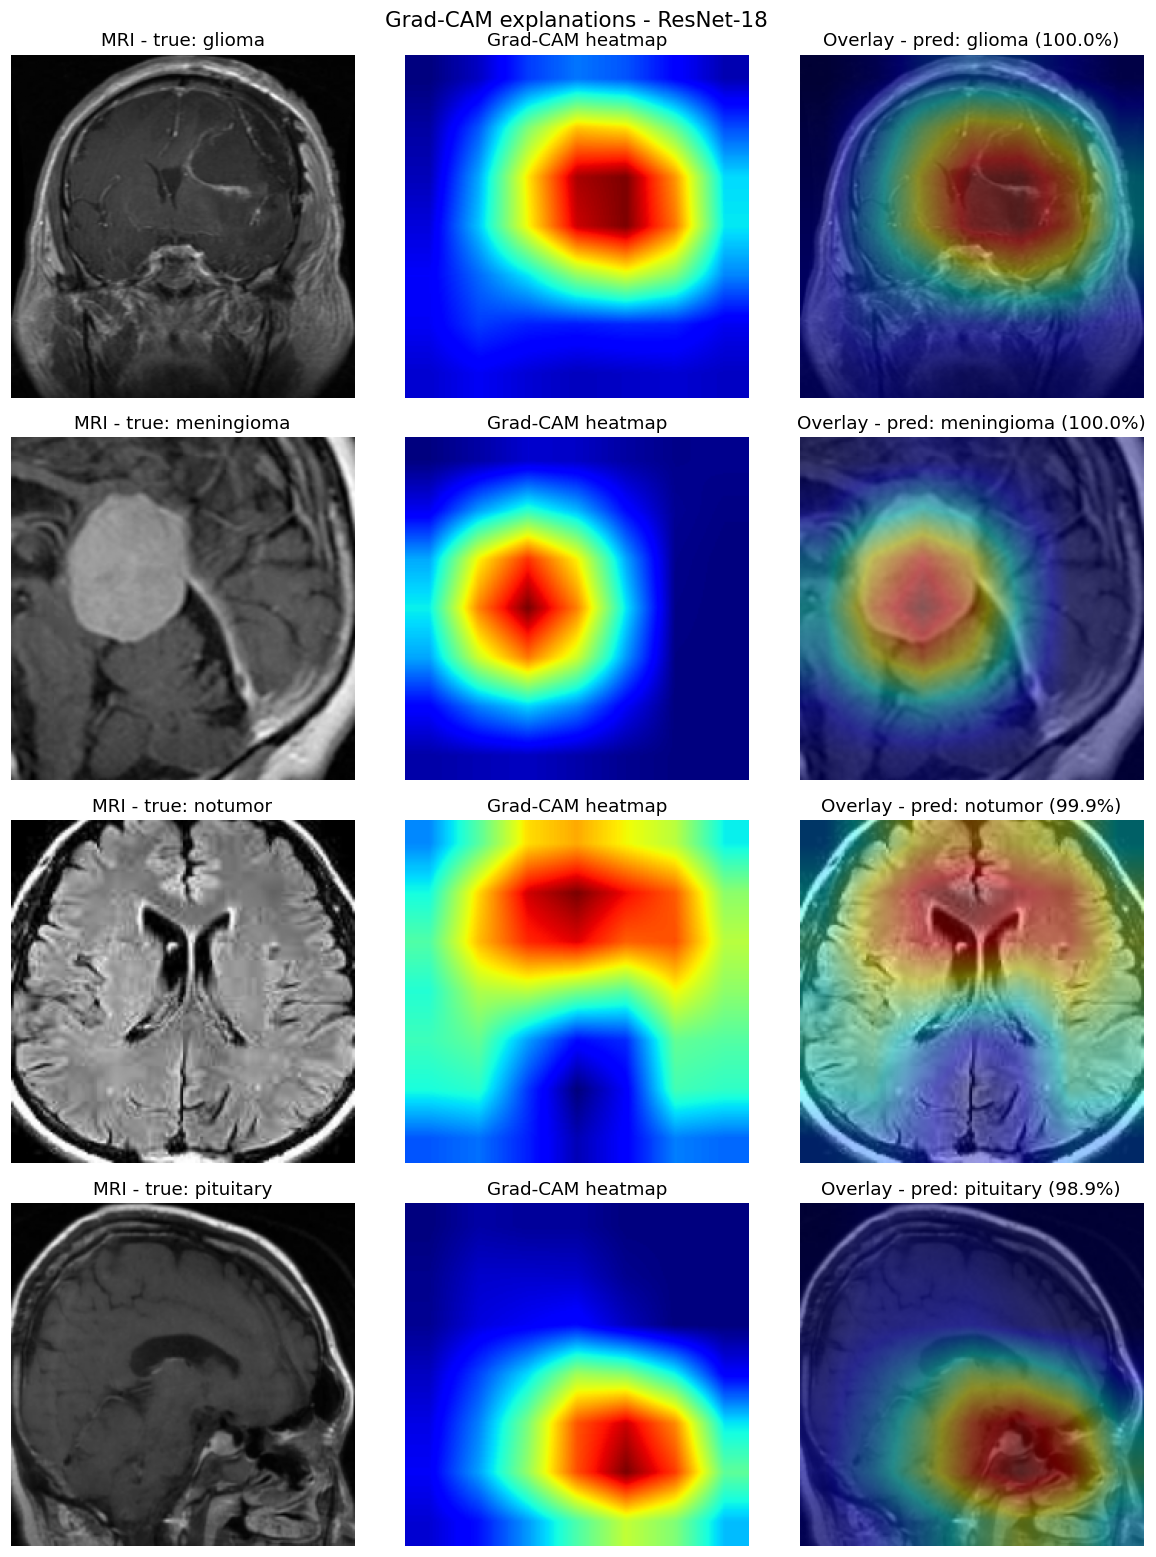

In [ ]:
# =============================================================
# CELL 27 - GRAD-CAM HEATMAPS OF THE BEST MODEL (ONE IMAGE PER CLASS)
# =============================================================
rng = np.random.default_rng(7)
chosen = []
for k in range(NUM_CLASSES):
    ok = np.where((y_test == k) & (best_pred == k))[0]
    chosen.append(int(rng.choice(ok)) if len(ok) else int(np.where(y_test == k)[0][0]))

fig, axes = plt.subplots(len(chosen), 3, figsize=(11, 3.6 * len(chosen)))
for r, idx in enumerate(chosen):
    gray, cam, cls, conf = gradcam_for(BEST_NAME, idx)
    axes[r, 0].imshow(gray, cmap="gray"); axes[r, 0].set_title(f"MRI - true: {CLASS_NAMES[y_test[idx]]}")
    axes[r, 1].imshow(cam, cmap="jet"); axes[r, 1].set_title("Grad-CAM heatmap")
    axes[r, 2].imshow(overlay(gray, cam)); axes[r, 2].set_title(f"Overlay - pred: {CLASS_NAMES[cls]} ({conf * 100:.1f}%)")
    for a in axes[r]: a.axis("off")
plt.suptitle(f"Grad-CAM explanations - {BEST_NAME}", fontsize=14)
plt.tight_layout()
plt.savefig(OUT / "gradcam_best_model.png", bbox_inches="tight")
plt.show()

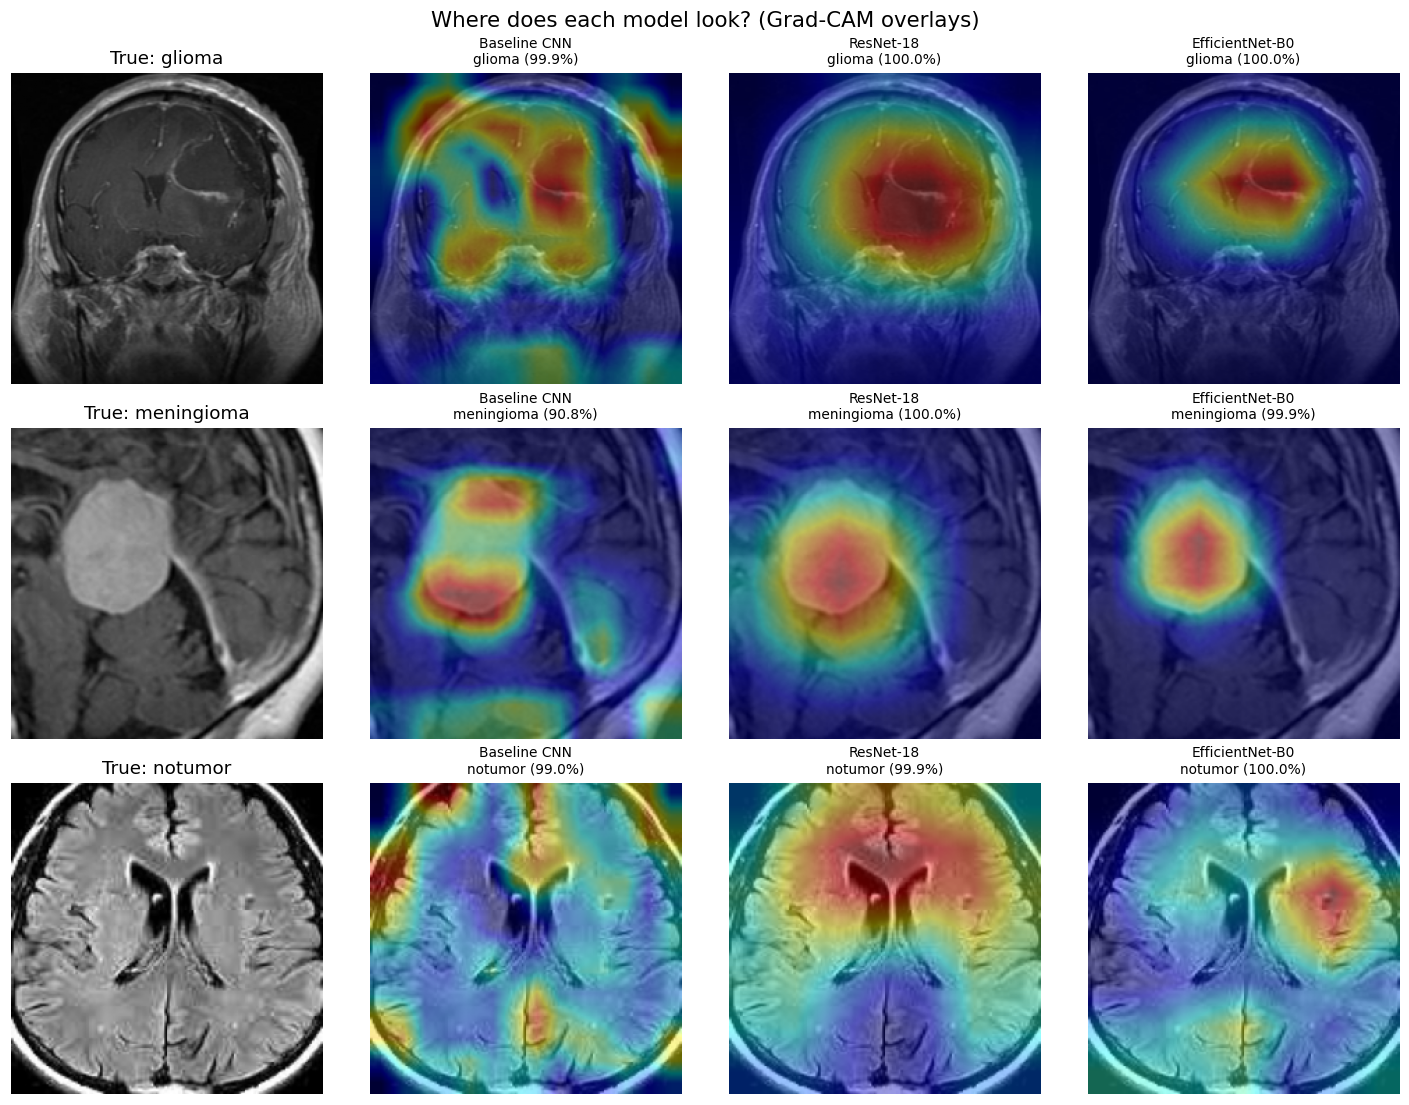

In [ ]:
# =============================================================
# CELL 28 - GRAD-CAM COMPARISON ACROSS THE THREE MODELS
# =============================================================
compare_idx = chosen[:3]
names = list(MODELS.keys())
fig, axes = plt.subplots(len(compare_idx), len(names) + 1, figsize=(3.3 * (len(names) + 1), 3.4 * len(compare_idx)))
for r, idx in enumerate(compare_idx):
    axes[r, 0].imshow(cv2.resize(X_test[idx], (S, S)), cmap="gray")
    axes[r, 0].set_title(f"True: {CLASS_NAMES[y_test[idx]]}")
    for c, name in enumerate(names, start=1):
        gray, cam, cls, conf = gradcam_for(name, idx)
        axes[r, c].imshow(overlay(gray, cam))
        axes[r, c].set_title(f"{name}\n{CLASS_NAMES[cls]} ({conf * 100:.1f}%)", fontsize=9)
    for a in axes[r]: a.axis("off")
plt.suptitle("Where does each model look? (Grad-CAM overlays)", fontsize=14)
plt.tight_layout()
plt.savefig(OUT / "gradcam_comparison.png", bbox_inches="tight")
plt.show()

## G. Inference Demo and Final Summary

Te-gl_348.jpg          true=glioma      predicted=glioma      confidence= 99.86%  glioma=99.86%  meningioma=0.11%  notumor=0.02%  pituitary=0.00%
Te-me_53.jpg           true=meningioma  predicted=meningioma  confidence= 99.99%  glioma=0.01%  meningioma=99.99%  notumor=0.00%  pituitary=0.00%
Te-no_310.jpg          true=notumor     predicted=notumor     confidence= 99.64%  glioma=0.03%  meningioma=0.30%  notumor=99.64%  pituitary=0.02%
Te-pi_1.jpg            true=pituitary   predicted=pituitary   confidence= 99.77%  glioma=0.00%  meningioma=0.23%  notumor=0.00%  pituitary=99.77%


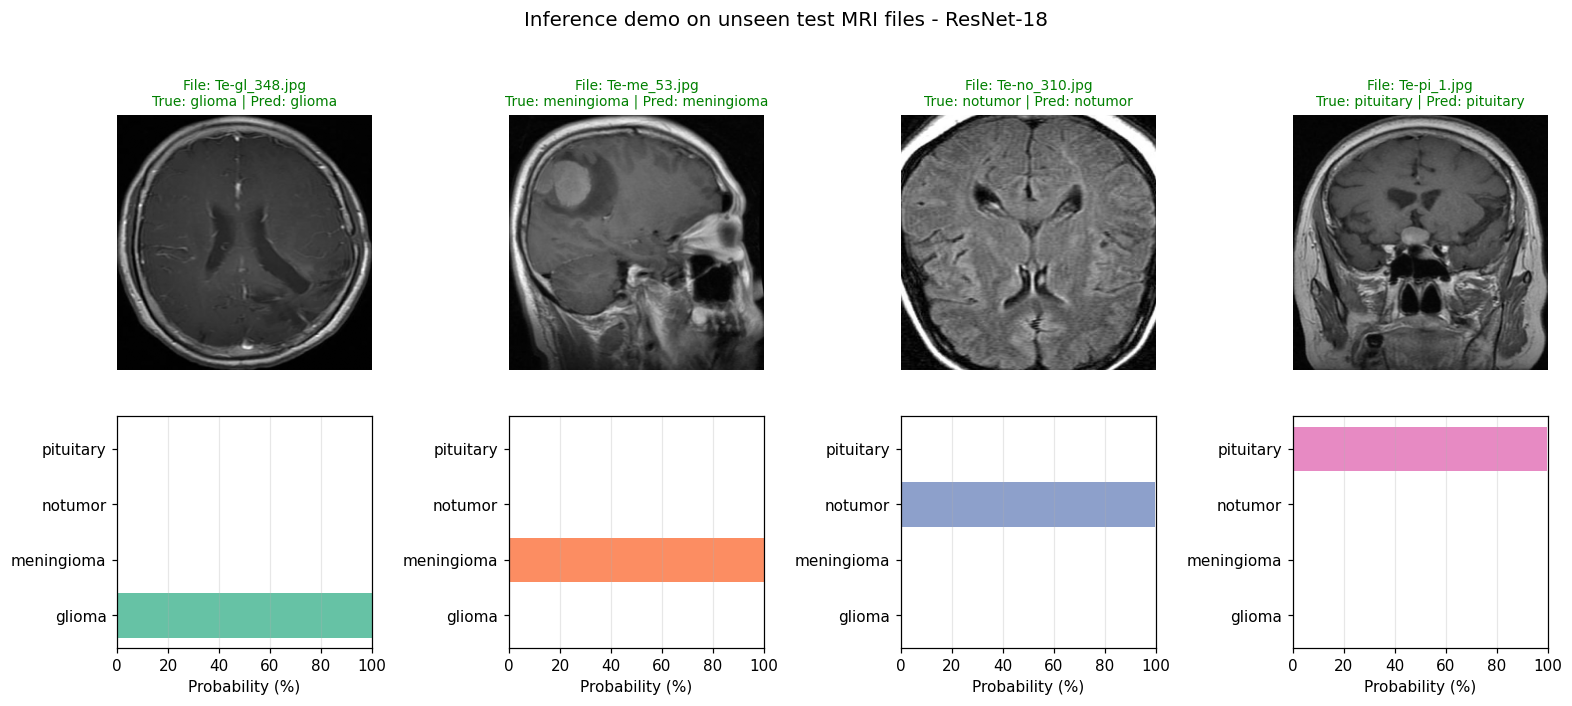

In [ ]:
# =============================================================
# CELL 29 - INFERENCE ON NEW MRI FILES (FULL PIPELINE)
# =============================================================
@torch.no_grad()
def predict_mri(path, model=best_model):
    """Raw image file -> crop -> resize -> normalise -> model -> class probabilities."""
    img = load_preprocessed(path)
    x = eval_tf(img).unsqueeze(0).to(DEVICE)
    model.eval()
    prob = F.softmax(model(x).float(), dim=1)[0].cpu().numpy()
    return img, prob

demo = test_df.groupby("label").sample(1, random_state=11).reset_index(drop=True)
fig, axes = plt.subplots(2, len(demo), figsize=(3.6 * len(demo), 6.5), gridspec_kw={"height_ratios": [3, 2]})
for c, row in demo.iterrows():
    img, prob = predict_mri(row.path)
    pred = CLASS_NAMES[prob.argmax()]
    axes[0, c].imshow(img, cmap="gray"); axes[0, c].axis("off")
    axes[0, c].set_title(f"File: {Path(row.path).name}\nTrue: {row.label} | Pred: {pred}", fontsize=9,
                         color="green" if pred == row.label else "red")
    axes[1, c].barh(CLASS_NAMES, prob * 100, color=palette)
    axes[1, c].set_xlim(0, 100); axes[1, c].set_xlabel("Probability (%)"); axes[1, c].grid(axis="x", alpha=0.3)
    print(f"{Path(row.path).name:<22} true={row.label:<11} predicted={pred:<11} confidence={prob.max() * 100:6.2f}%  "
          + "  ".join(f"{n}={p * 100:.2f}%" for n, p in zip(CLASS_NAMES, prob)))
plt.suptitle(f"Inference demo on unseen test MRI files - {BEST_NAME}", fontsize=13)
plt.tight_layout()
plt.savefig(OUT / "inference_demo.png", bbox_inches="tight")
plt.show()

In [ ]:
# =============================================================
# CELL 30 - SAVE RESULTS AND PRINT FINAL SUMMARY
# =============================================================
summary = {
    "dataset": CONFIG["dataset"],
    "classes": CLASS_NAMES,
    "images_total": int(len(df_all)),
    "train_images_after_cleaning": int(len(train_pool)),
    "train_val_test": [int(len(y_tr)), int(len(y_va)), int(len(y_test))],
    "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "best_model": BEST_NAME,
    "results": results_df.to_dict(orient="records"),
    "epochs_run": {n: int(len(h)) for n, h in HISTORIES.items()},
}
with open(OUT / "summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("=" * 70)
print("NEUROSCAN-AI - FINAL SUMMARY")
print("=" * 70)
print(f"Dataset          : {CONFIG['dataset']}")
print(f"Classes          : {', '.join(CLASS_NAMES)}")
print(f"Images           : {len(df_all)} total | train {len(y_tr)} | val {len(y_va)} | test {len(y_test)}")
print(f"Hardware         : {summary['device']}")
for r in summary["results"]:
    print(f"{r['Model']:<17}: accuracy {r['Test accuracy'] * 100:6.2f}% | macro F1 {r['Macro F1'] * 100:6.2f}% | "
          f"AUC {r['Macro ROC-AUC']:.4f} | {r['Parameters (M)']:.2f} M params | {r['Inference (ms/image)']:.2f} ms/image")
print(f"Best model       : {BEST_NAME}")
print("\nSaved files:")
for p in sorted(OUT.iterdir()):
    print(f"  {p.name:<40} {p.stat().st_size / 1e6:8.2f} MB")

NEUROSCAN-AI - FINAL SUMMARY
Dataset          : masoudnickparvar/brain-tumor-mri-dataset
Classes          : glioma, meningioma, notumor, pituitary
Images           : 7200 total | train 4614 | val 815 | test 1600
Hardware         : Tesla T4
Baseline CNN     : accuracy  87.38% | macro F1  87.11% | AUC 0.9642 | 1.17 M params | 3.25 ms/image
ResNet-18        : accuracy  95.12% | macro F1  95.04% | AUC 0.9903 | 11.18 M params | 3.57 ms/image
EfficientNet-B0  : accuracy  96.00% | macro F1  95.94% | AUC 0.9932 | 4.01 M params | 10.86 ms/image
Best model       : ResNet-18

Saved files:
  augmented_batch.png                          0.56 MB
  baseline_cnn.pt                              4.72 MB
  best_model_classification_report.csv         0.00 MB
  class_distribution.png                       0.04 MB
  confusion_matrix.png                         0.05 MB
  efficientnet_b0.pt                          16.33 MB
  gradcam_best_model.png                       1.21 MB
  gradcam_comparison.png      

### Done
Download this notebook **with outputs**: File ▸ Download ▸ Download .ipynb, and share it for the report.